# 1. Setup & Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

np.set_printoptions(legacy="1.25")

## Calling pickles

In [2]:
charge_df = pd.read_pickle("charge_df_EDA.pkl")
discharge_df = pd.read_pickle("discharge_df_EDA.pkl")
eis_df = pd.read_pickle("eis_df_EDA.pkl")
discharge_eis_clean = pd.read_pickle("discharge_eis_clean.pkl")

# 2. Correlation Analysis.

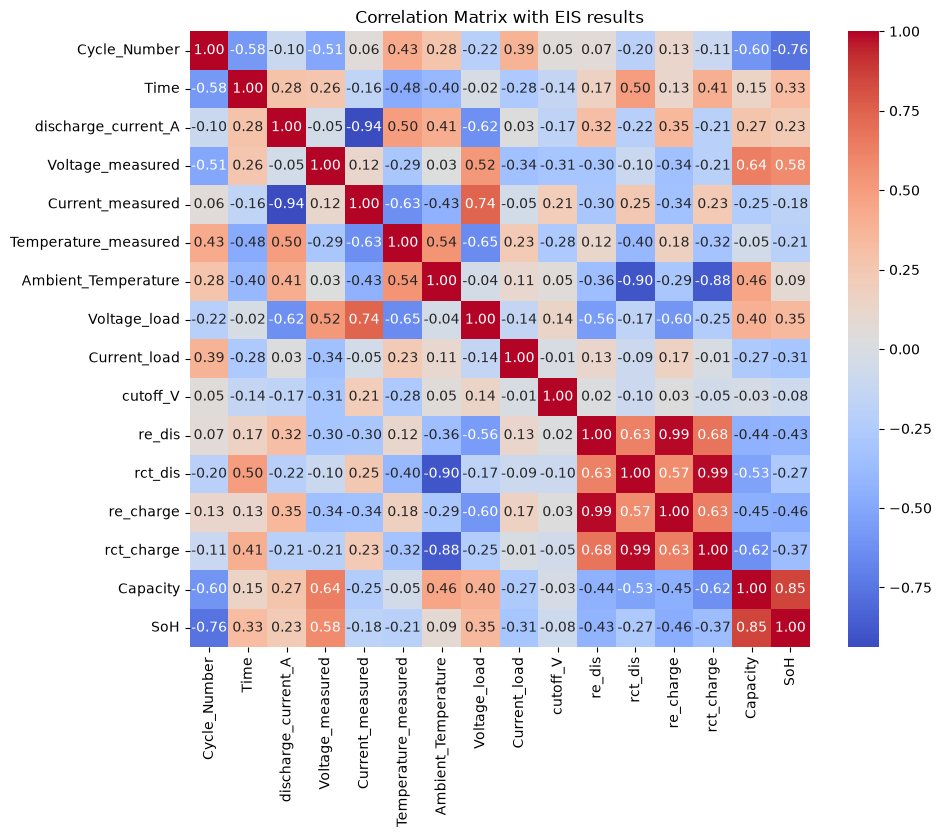

In [4]:
# Correlation heatmap of all numeric columns, including the EIS-derived resistances
numeric_df = discharge_eis_clean.select_dtypes(include='number')
corr_matrix = numeric_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix with EIS results")
plt.show()

We observe that (ignoring the Capacity as SoH is directly determined by it) there is a great positive correlation between Time_rel_s, measured and load voltages and currents with the SoH. The EIS parameters, R_Electrolyte and R_Charge_Transfer have negative correlation with the SoH. 

# 3. Preprocess for Modeling
One-hot encode `Discharge_Type`, split into train/test **by Cell_ID**.

Turning Discharge Types into dummy variables.

In [5]:
# One-hot encode Discharge_Type and drop the raw Capacity column (SoH is the modeling target)
discharge_eis_clean = pd.get_dummies(discharge_eis_clean, columns=['Discharge_Type'], drop_first=True)
discharge_eis_clean.drop(columns=['Capacity'], inplace=True)
discharge_eis_clean.head()

,Cell_ID,Cycle_Number,Time,discharge_current_A,Voltage_measured,Current_measured,Temperature_measured,Ambient_Temperature,Voltage_load,Current_load,cutoff_V,re_dis,rct_dis,re_charge,rct_charge,SoH,Discharge_Type_Constant_2A,Discharge_Type_Constant_4A,Discharge_Type_Square_4A
19,B0005,41,3591.734,2.0,0.928874,-2.016847,13.888784,24.0,2.448323,-1.842201,2.7,0.046687,0.076275,0.044669,0.069456,0.994904,True,False,False
20,B0005,45,3552.297,2.0,0.969583,-2.016191,14.070169,24.0,2.474068,-1.861526,2.7,0.046195,0.074534,0.044843,0.067972,0.995114,True,False,False
21,B0005,49,3531.578,2.0,0.930138,-2.016760,13.948276,24.0,2.480037,-1.860800,2.7,0.045991,0.073427,0.045101,0.068528,0.989060,True,False,False
22,B0005,53,3492.907,2.0,0.907087,-2.016023,13.949235,24.0,2.492449,-1.870012,2.7,0.045217,0.074648,0.044172,0.068044,0.983460,True,False,False
23,B0005,57,3511.594,2.0,0.907673,-2.017191,14.110271,24.0,2.479261,-1.860064,2.7,0.044910,0.073957,0.043787,0.068450,0.983100,True,False,False


In [6]:
# Separating by cell ID to prevent data leakage
cell_ids = discharge_eis_clean['Cell_ID'].unique()
train_ids, test_ids = train_test_split(cell_ids, test_size=0.3, random_state=42)

train_df = discharge_eis_clean[discharge_eis_clean['Cell_ID'].isin(train_ids)].copy()
test_df  = discharge_eis_clean[discharge_eis_clean['Cell_ID'].isin(test_ids)].copy()

# Keep raw Cell_ID ONLY for group-aware CV; it is not a feature
train_groups = train_df['Cell_ID'].values

X_train = train_df.drop(columns=['SoH', 'Cell_ID'])
y_train = train_df['SoH']
X_test  = test_df.drop(columns=['SoH', 'Cell_ID'])
y_test  = test_df['SoH']

print("Training features shape:", X_train.shape)
print("Test features shape:", X_test.shape)
print(X_train.columns.tolist())  # sanity check: no Cell_ID_* columns

Training features shape: (199, 17)
Test features shape: (280, 17)
['Cycle_Number', 'Time', 'discharge_current_A', 'Voltage_measured', 'Current_measured', 'Temperature_measured', 'Ambient_Temperature', 'Voltage_load', 'Current_load', 'cutoff_V', 're_dis', 'rct_dis', 're_charge', 'rct_charge', 'Discharge_Type_Constant_2A', 'Discharge_Type_Constant_4A', 'Discharge_Type_Square_4A']


# 4. Define Model Pipelines, CV Strategy & Hyperparameter Grids
Build scikit-learn `Pipeline`s for Random Forest, XGBoost, and LightGBM, set up 5-fold CV, and define the `GridSearchCV` parameter grids for each model.

In [7]:
# Build a scikit-learn Pipeline for the requested model ('rf', 'xgb', or 'lgb')
def get_pipeline(model_name):
    """
    model_name: 'rf', 'xgb', 'lgb'
    """
    if model_name == 'rf':
        return Pipeline([
            ('scaler', StandardScaler()),  # optional for tree-based models
            ('model', RandomForestRegressor(n_estimators=100, random_state=42))
        ])

    elif model_name == 'xgb':
        return Pipeline([
            ('scaler', StandardScaler()),  # optional
            ('model', XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42))
        ])

    elif model_name == 'lgb':
        return Pipeline([
                        ('model', LGBMRegressor(n_estimators=100, max_depth=-1, learning_rate=0.1, random_state=42))
        ])

    else:
        raise ValueError("model_name must be one of: 'rf', 'xgb', 'lgb'")

rf_pipeline = get_pipeline('rf')
xgb_pipeline = get_pipeline('xgb')
lgb_pipeline = get_pipeline('lgb')

In [8]:
# 5-fold group-aware CV so rows from the same cell never span train/validation folds
from sklearn.model_selection import GroupKFold
cv = GroupKFold(n_splits=5)

In [9]:
# Hyperparameter grids for the Random Forest, XGBoost, and LightGBM grid searches
rf_param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

xg_param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [3, 6, 9],
    'model__learning_rate': [0.01, 0.1, 0.2],
    'model__subsample': [0.7, 0.8, 1.0]
}

lgb_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10],
    'model__learning_rate': [0.05, 0.1],
    'model__num_leaves': [31, 50],
    'model__min_child_samples': [5, 10]
}

# 5. Train & Evaluate Models
## 5.1 Random Forest

Random Forest Regressor

In [10]:
# Grid-search the Random Forest pipeline with group-aware CV and report the best params/score
rf_model = GridSearchCV(estimator=rf_pipeline, param_grid=rf_param_grid, cv=cv, scoring='neg_mean_squared_error', verbose=2, n_jobs=-1)
rf_model.fit(X_train, y_train, groups=train_groups)
print("Best parameters:", rf_model.best_params_)
print("Best score (MSE):", -rf_model.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best score (MSE): 0.008547656027477021


In [11]:
# Print and return R2/MSE/RMSE/MAE for a set of predictions
def regression_report(y_true, y_pred):
    from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"R²: {r2:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    return r2, mse, rmse, mae

In [12]:
# Evaluate the tuned Random Forest on the held-out test cells
y_pred_rf = rf_model.predict(X_test)
regression_report(y_test, y_pred_rf)

R²: 0.7041
MSE: 0.0038
RMSE: 0.0613
MAE: 0.0479


(0.7041226895761303,
 0.003751761141635958,
 0.06125162154291067,
 0.047917154990633454)

## 5.2 XGBoost

XGBoost

In [13]:
# Grid-search the XGBoost pipeline with group-aware CV and report the best params/score
xg_model = GridSearchCV(estimator=xgb_pipeline, param_grid=xg_param_grid, cv=cv, scoring='neg_mean_squared_error', verbose=2, n_jobs=-1)
xg_model.fit(X_train, y_train, groups=train_groups)
print("Best parameters:", xg_model.best_params_)
print("Best score (MSE):", -xg_model.best_score_)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best parameters: {'model__learning_rate': 0.01, 'model__max_depth': 9, 'model__n_estimators': 100, 'model__subsample': 0.7}
Best score (MSE): 0.007251053550220478


In [14]:
# Evaluate the tuned XGBoost model on the held-out test cells
y_pred_xg = xg_model.predict(X_test)
regression_report(y_test, y_pred_xg)

R²: 0.4198
MSE: 0.0074
RMSE: 0.0858
MAE: 0.0681


(0.41976105569049915,
 0.007357502070725309,
 0.08577588280353231,
 0.06811116573023157)

## 5.3 LightGBM

LightGBM

In [15]:
# Grid-search the LightGBM pipeline with group-aware CV and report the best params/score
lg_model = GridSearchCV(estimator=lgb_pipeline, param_grid=lgb_param_grid, cv=cv, scoring='neg_mean_squared_error', verbose=2, n_jobs=-1)
lg_model.fit(X_train, y_train, groups=train_groups)
print("Best parameters:", lg_model.best_params_)
print("Best score (MSE):", -lg_model.best_score_)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000130 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 754
[LightGBM] [Info] Number of data points in the train set: 199, number of used features: 17
[LightGBM] [Info] Start training from score 0.849795
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM]

In [16]:
# Evaluate the tuned LightGBM model on the held-out test cells
y_pred_lg = lg_model.predict(X_test)
regression_report(y_test, y_pred_lg)

R²: 0.7835
MSE: 0.0027
RMSE: 0.0524
MAE: 0.0387


(0.7835342567615596,
 0.0027448125806398757,
 0.05239095895896424,
 0.03870142611449571)

## 5.4 Compare Model Results
Collect R2/MSE/RMSE/MAE across all three models and plot them side by side.

R²: 0.7041
MSE: 0.0038
RMSE: 0.0613
MAE: 0.0479
R²: 0.4198
MSE: 0.0074
RMSE: 0.0858
MAE: 0.0681
R²: 0.7835
MSE: 0.0027
RMSE: 0.0524
MAE: 0.0387


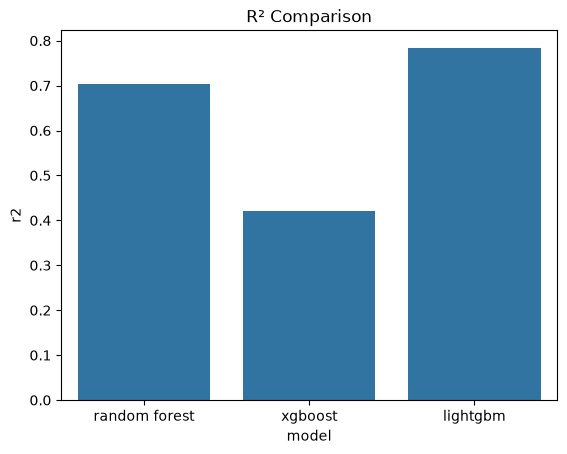

In [17]:
# Collect R2/MSE/RMSE/MAE for all three models and compare R2 side by side
r2 = []
mse = []
rmse = []
mae = []
r2_rf, mse_rf, rmse_rf, mae_rf = regression_report(y_test, y_pred_rf)
r2.append(r2_rf)
mse.append(mse_rf)
rmse.append(rmse_rf)
mae.append(mae_rf)
r2_xg, mse_xg, rmse_xg, mae_xg = regression_report(y_test, y_pred_xg)
r2.append(r2_xg)
mse.append(mse_xg)
rmse.append(rmse_xg)
mae.append(mae_xg)
r2_lg, mse_lg, rmse_lg, mae_lg = regression_report(y_test, y_pred_lg)
r2.append(r2_lg)
mse.append(mse_lg)
rmse.append(rmse_lg)
mae.append(mae_lg)

results_df = pd.DataFrame({
    "model": ["random forest", "xgboost", "lightgbm"],
    "r2": r2,
    "mse": mse,
    "rmse": rmse,
    "mae": mae
})


sns.barplot(data=results_df, x="model", y="r2")
plt.title("R² Comparison")
plt.show()


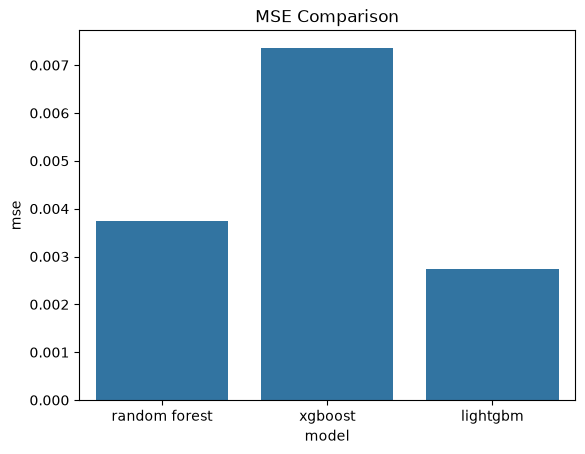

In [18]:
# Compare MSE side by side across all three models
sns.barplot(data=results_df, x="model", y="mse")
plt.title("MSE Comparison")
plt.show()

**LightGBM was the best-performing model**, beating both Random Forest and XGBoost on every metric (R² = 0.78 vs. 0.70 (RF) and 0.42 (xgboost); also lowest MSE, RMSE, and MAE) after hyperparameter tuning.

## 5.5. Feature Importance of the Three Models

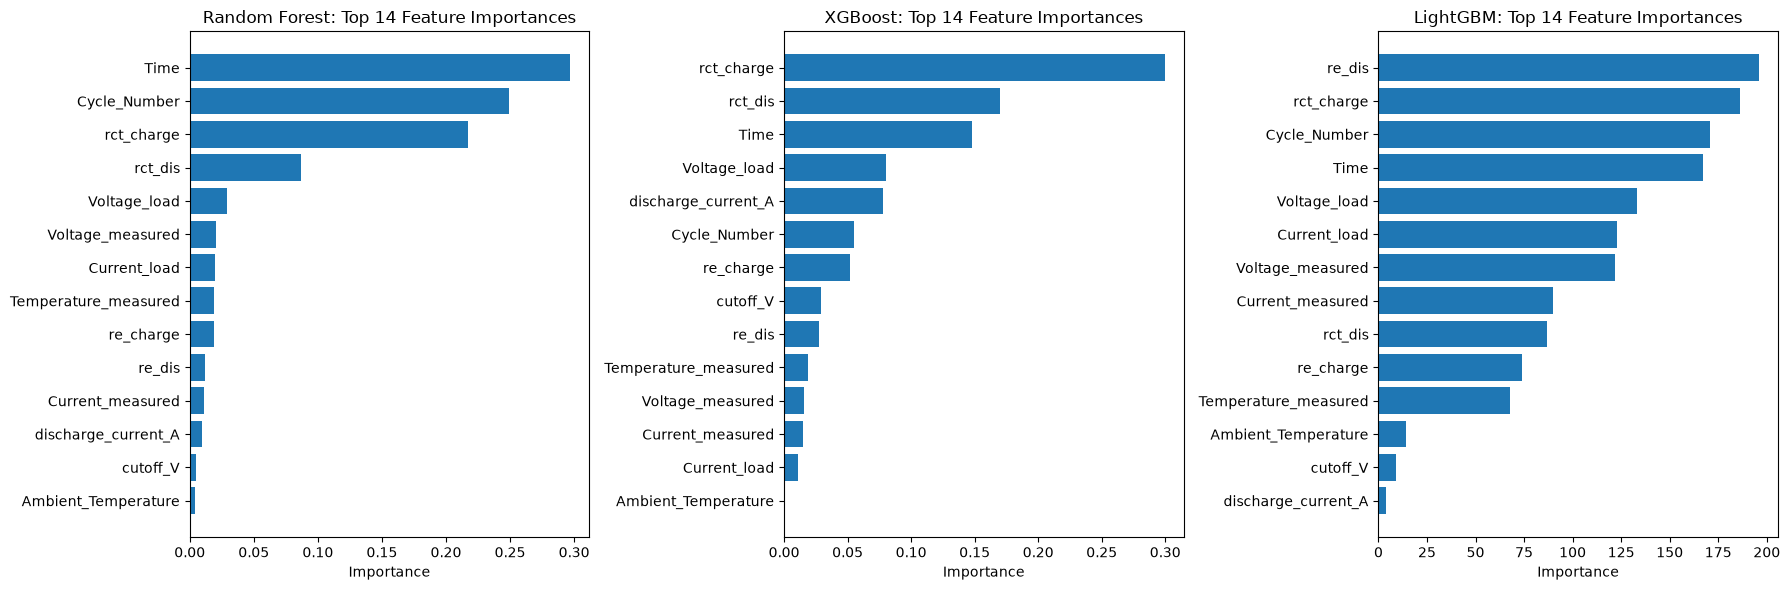

In [19]:
# Pull the fitted estimator out of each GridSearchCV/Pipeline and grab its feature importances.
def get_importances(fitted_grid_search, feature_names):
    model = fitted_grid_search.best_estimator_.named_steps['model']
    imp = pd.Series(model.feature_importances_, index=feature_names)
    return imp.sort_values(ascending=False)

feature_names = X_train.columns

imp_rf = get_importances(rf_model, feature_names)
imp_xg = get_importances(xg_model, feature_names)
imp_lg = get_importances(lg_model, feature_names)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, imp, name in zip(axes, [imp_rf, imp_xg, imp_lg], ["Random Forest", "XGBoost", "LightGBM"]):
    top_n = imp.head(14)  
    ax.barh(top_n.index[::-1], top_n.values[::-1])
    ax.set_title(f"{name}: Top 14 Feature Importances")
    ax.set_xlabel("Importance")

plt.tight_layout()
plt.show()

For LightGBM, the **electrolytic resistance after a discharge cycle (re_dis)** is the most important feature. 
For XGBoost, the **charge transfer resistance after a charging cycle (rct_charge)** is the most important feature.
For Random Forest, **the experiment duration** is the most important features.

## 5.6. Predicted vs Actual SoH Plot

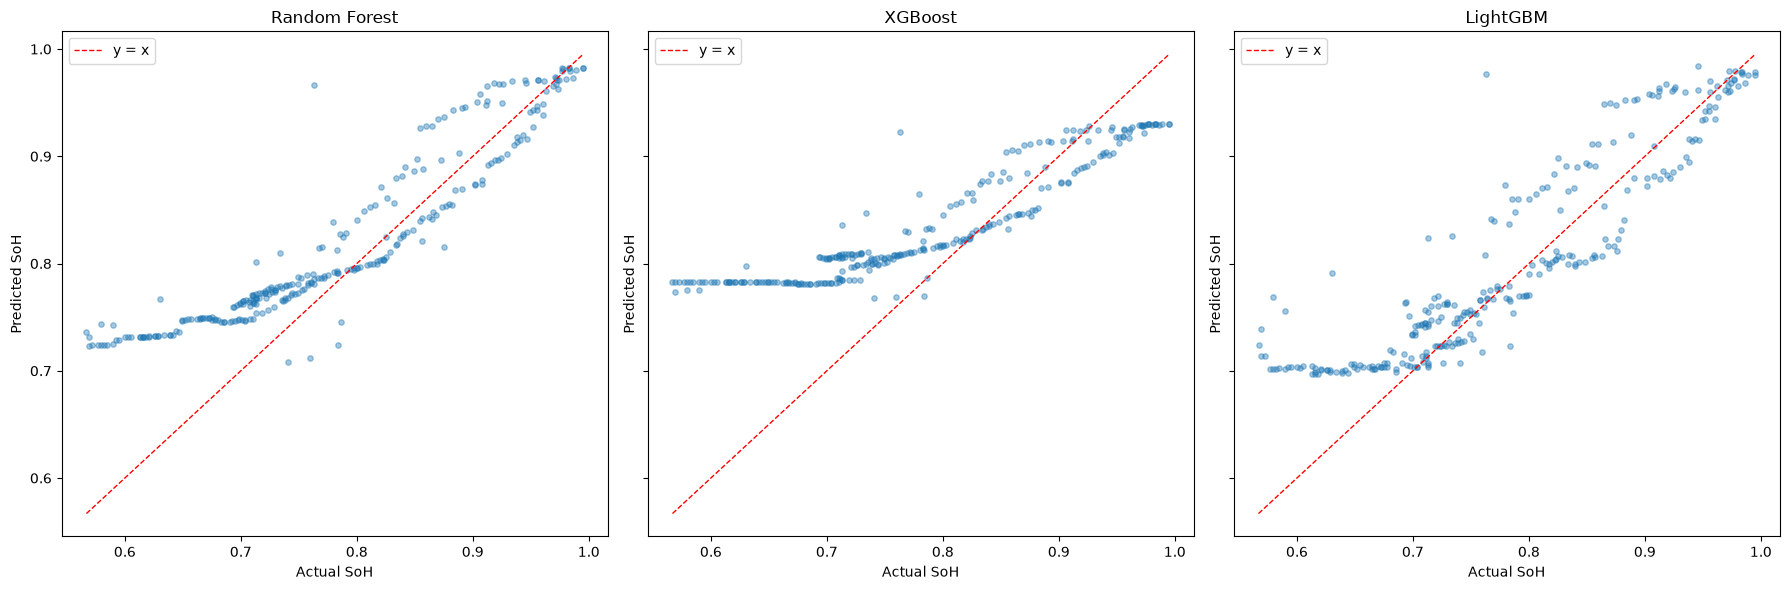

In [20]:
# Bar charts of aggregate R²/MSE hide systematic bias — e.g. a model that's
# accurate mid-range but drifts near end-of-life (SoH < 0.7), which is the
# region that matters most for a real SoH predictor. This shows that directly.
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
preds = [y_pred_rf, y_pred_xg, y_pred_lg]
names = ["Random Forest", "XGBoost", "LightGBM"]

for ax, y_pred, name in zip(axes, preds, names):
    ax.scatter(y_test, y_pred, alpha=0.4, s=15)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1, label='y = x')
    ax.set_xlabel("Actual SoH")
    ax.set_ylabel("Predicted SoH")
    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()

All three models performs reasonably well up to State of Health of around 0.8. XGBoost was the poorest performing model, frequently predicting a SoH of near 0.8 despite the actual SoH being far lower than that. Random Forest's prediction began deviating while the actual SoH was above 0.7, while LightGBM predicted it quite well up to SoH of 0.7. 

# 6. Further Comments

Initially, there was a part 4 of this project where the author attempted to fit the existing EIS results in the dataset to an equivalent circuit model (ECM). This was planned in order to create more features for the dataset: currently, the only features extracted from ECM fitting are electrolytic resistance (Re) and charge transfer resistance (Rct). By fitting to an ECM, the author hoped to gain more features: double layer capacitance, diffusion element, etc., and afterwards the data would be trained again to be able to predict SoH even better. However, the EIS measurements included in the dataset had huge KK error residuals in the lower and higher frequency region, and removing the problematic data points would be removing almost half of the available datapoints in the spectra, therefore the author did not go through with it. Furthermore, such removals would yield a Nyquist plot with obscure shapes, meaning judging if the model was successfully fitted or not would involve a lot of guesswork.